# What pushes a Batman story up BatChat's list?

Which creators, characters and publication patterns shape the model's predictions—and do the outside audiences show similar patterns?

**Rank 1 is best.** Read effect size alongside frequency and uncertainty.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

In [1]:
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
pd.set_option("display.max_rows", 20)
pd.set_option("display.min_rows", 10)
pd.set_option("styler.render.max_rows", 20)

sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
N = len(stories)
# Higher = more liked, so weights read the same way for BatChat and for star ratings.
stories["batchat_score"] = N - stories["rank"]

## Size, direction and support

A large coefficient need not matter often. The SHAP panel separates overall influence from direction when present, with story/group counts, sampling intervals and variation across held-out fits.

## Inputs

The ridge model uses publication year, issue count, format, selected-story creators and cast. Names need eight training stories to receive a coefficient; rarer format categories share a pooled indicator. Outside-audience charts also require eight-story support; their smaller fits keep the existing three-story name threshold. It reduces rare-feature noise, but eight stories from one run can still confound a creator with their era or collaborators.

In [2]:
MIN_STORIES = 8
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = {"narrative_" + r: r[:-1] for r in ROLES}  # column -> label, e.g. "writer"
CAST = {"featured_entity_ids": "featured", "antagonists_entity_ids": "antagonist"}
WHEN = ["cover_year_start", "issue_count"]

X = stories[["medium", "format_hint", *WHEN, *NAMES, *CAST]].copy()
X[[*NAMES, *CAST]] = X[[*NAMES, *CAST]].fillna("")


def model(min_df=MIN_STORIES):
    """Ridge regression on scaled numbers, one-hot format, and 0/1 name columns."""
    return make_pipeline(
        ColumnTransformer(
            [
                ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), WHEN),
                (
                    "format",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=MIN_STORIES),
                    ["medium", "format_hint"],
                ),
                *[
                    (
                        label,
                        CountVectorizer(
                            token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=min_df
                        ),
                        col,
                    )
                    for col, label in {**NAMES, **CAST}.items()
                ],
            ]
        ),
        RidgeCV(alphas=np.logspace(-1, 3, 9)),
    )


def pretty(feature):
    """'writer__Frank Miller' -> 'Frank Miller (writer)'; characters lose their universe tag."""
    kind, _, value = feature.partition("__")
    if kind in {"num", "format"}:
        return (
            value.replace("format_hint_", "format: ")
            .replace("cover_year_start", "cover year")
            .replace("issue_count", "issue count")
        )
    return f"{value.split(' (')[0]} ({kind})"


def weights_of(fitted):
    """Keep distinct continuity coefficients separate; only actual SHAP contributions are summed."""
    labels = []
    for feature in fitted[0].get_feature_names_out():
        kind, _, value = feature.partition("__")
        labels.append(pretty(feature) if kind in {"num", "format"} else f"{value} ({kind})")
    return pd.Series(fitted[-1].coef_, index=labels)


def weight_bars(ax, weights, n, faded=()):
    """Horizontal bars of the n strongest positive and negative weights; `faded` names drawn grey."""
    top = pd.concat([weights.nlargest(n), weights.nsmallest(n)])
    top = top[~top.index.duplicated()].sort_values()
    colors = [GREY if name in faded else (BLUE if v > 0 else ORANGE) for name, v in top.items()]
    ax.barh(top.index, top, color=colors)
    ax.axvline(0, color=GREY, lw=1)
    ax.xaxis.set_major_locator(MaxNLocator(5))

## 1. Fitted coefficients

Positive coefficients point toward a better predicted rank. Grey marks coefficients failing the five-fold stability filter.

Continuity versions stay separate here. Adding their coefficients would describe activating every version together; the SHAP analysis instead combines their actual contributions story by story.

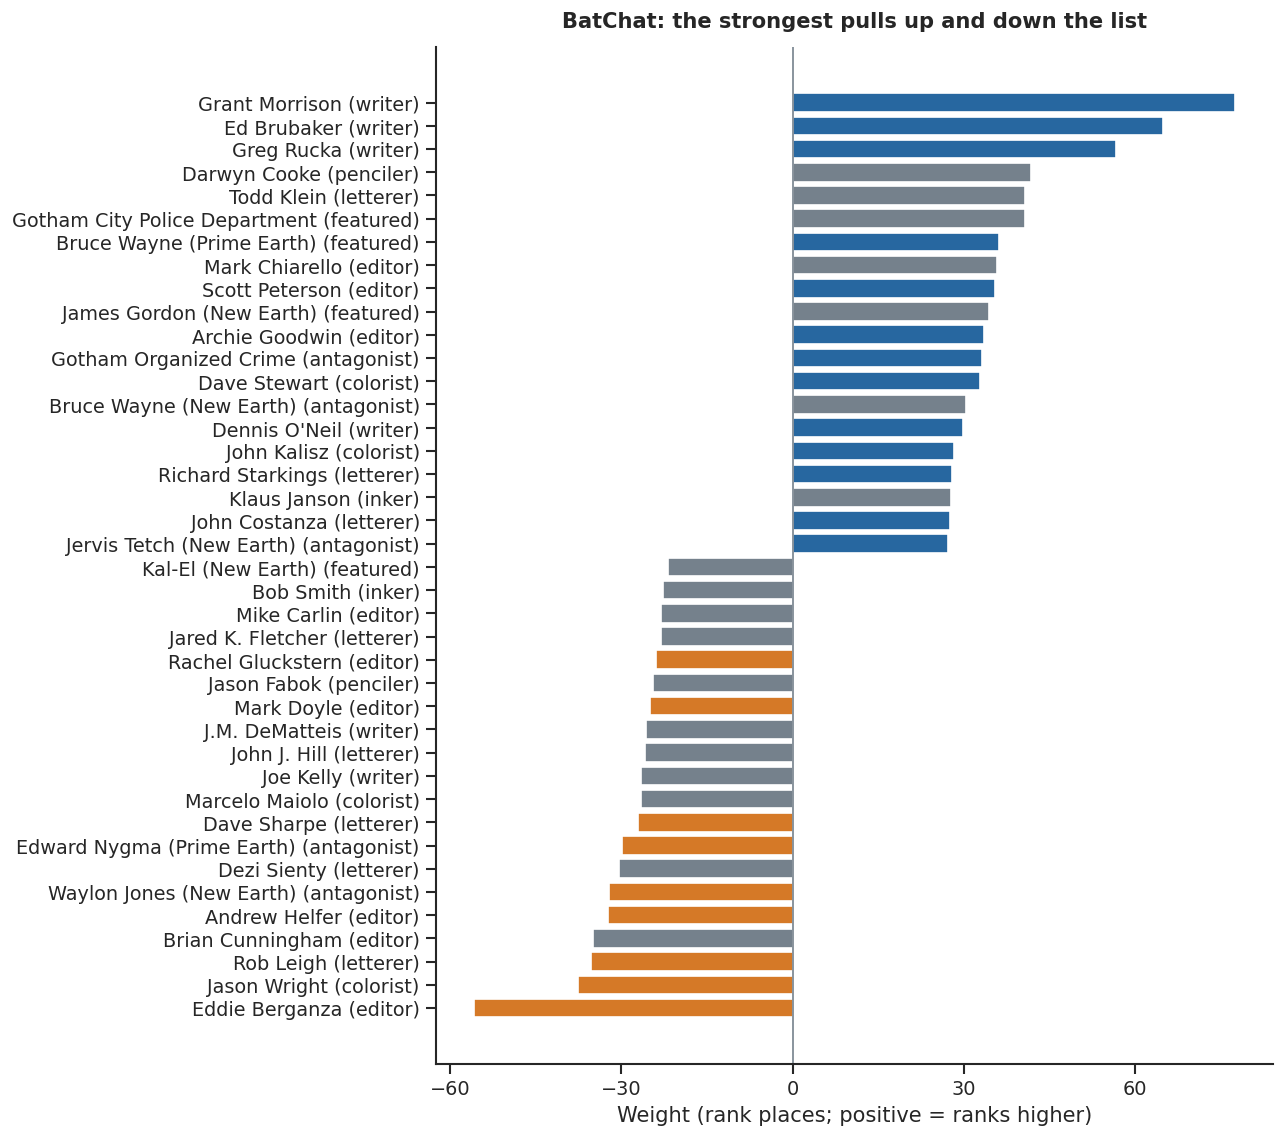

On stories it never saw, the model misses by about 174 places. 43 coefficients passed the stability check.


In [3]:
# Stories linked by a shared issue or episode stay in the same fold.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

y = stories.batchat_score
batchat_model = model().fit(X, y)
batchat_weights = weights_of(batchat_model)

# One fit per fold does triple duty: held-out predictions, the shuffle test, and the stability test.
blocks = {
    "Year + length": WHEN,
    "Format": ["medium", "format_hint"],
    "Writers": ["narrative_writers"],
    "Pencilers + inkers": ["narrative_pencilers", "narrative_inkers"],
    "Colors + letters + editors": [
        "narrative_colorists",
        "narrative_letterers",
        "narrative_editors",
    ],
    "Characters": list(CAST),
}
held_out = np.empty(N)
fold_models = []
shuffle_cost, fold_weights = [], []
rng = np.random.default_rng(0)
for k, (train, test) in enumerate(folds):
    fitted = model().fit(X.iloc[train], y.iloc[train])
    held_out[test] = fitted.predict(X.iloc[test])
    fold_models.append(fitted)
    fold_weights.append(weights_of(fitted).rename(k))
    base = mean_absolute_error(y.iloc[test], held_out[test])
    for block, cols in blocks.items():
        shuffled = X.iloc[test].copy()
        shuffled[cols] = shuffled[cols].sample(frac=1, random_state=rng.integers(1e6)).to_numpy()
        shuffle_cost.append(
            {
                "block": block,
                "worse by": mean_absolute_error(y.iloc[test], fitted.predict(shuffled)) - base,
            }
        )
shuffle_cost = pd.DataFrame(shuffle_cost)
fold_weights = pd.concat(fold_weights, axis=1).fillna(0)
stable = fold_weights.index[
    (np.sign(fold_weights).nunique(axis=1) == 1) & (fold_weights.abs().min(axis=1) > 10)
]
unstable = set(batchat_weights.index) - set(stable)

fig, ax = plt.subplots(figsize=(9, 11))
weight_bars(ax, batchat_weights, 20, faded=unstable)
ax.set(
    xlabel="Weight (rank places; positive = ranks higher)",
    title="BatChat: the strongest pulls up and down the list",
)
plt.show()
print(
    f"On stories it never saw, the model misses by about {mean_absolute_error(y, held_out):.0f} places. "
    f"{len(stable)} coefficients passed the stability check."
)

Compare coefficients with the observed rank distributions: the same writer's books can span most of the list.

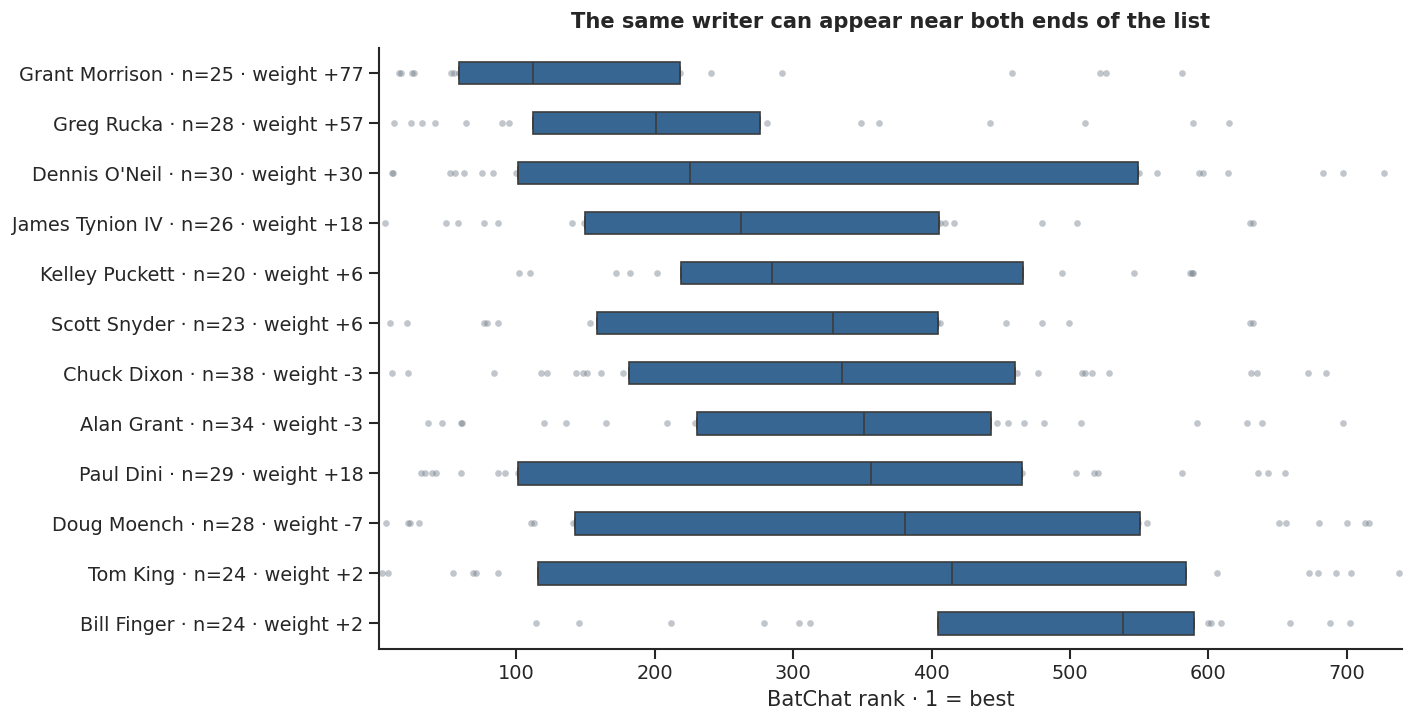

In [4]:
writers = stories.assign(writer=stories.narrative_writers.str.split("|")).explode("writer")
top = writers.writer.value_counts().head(12).index
chart = writers[writers.writer.isin(top)]
order = chart.groupby("writer")["rank"].median().sort_values().index
labels = {
    w: f"{w} · n={chart.writer.eq(w).sum()} · weight {batchat_weights.get(f'{w} (writer)', 0):+.0f}"
    for w in order
}
chart = chart.assign(label=chart.writer.map(labels))
fig, ax = plt.subplots(figsize=(11, 6.5))
common = dict(data=chart, x="rank", y="label", order=[labels[w] for w in order], ax=ax)
sns.stripplot(**common, color=GREY, alpha=0.45, size=4, jitter=False, zorder=0)
sns.boxplot(**common, color=BLUE, whis=0, showfliers=False, width=0.45)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    xlim=(1, N),
    title="The same writer can appear near both ends of the list",
)
plt.show()

## 2. How stable are those weights?

The shuffle test disrupts one input block in held-out stories and measures the increase in prediction error. The stability filter refits five times, retaining coefficients whose sign stays fixed and magnitude exceeds ten rank places in every fit.

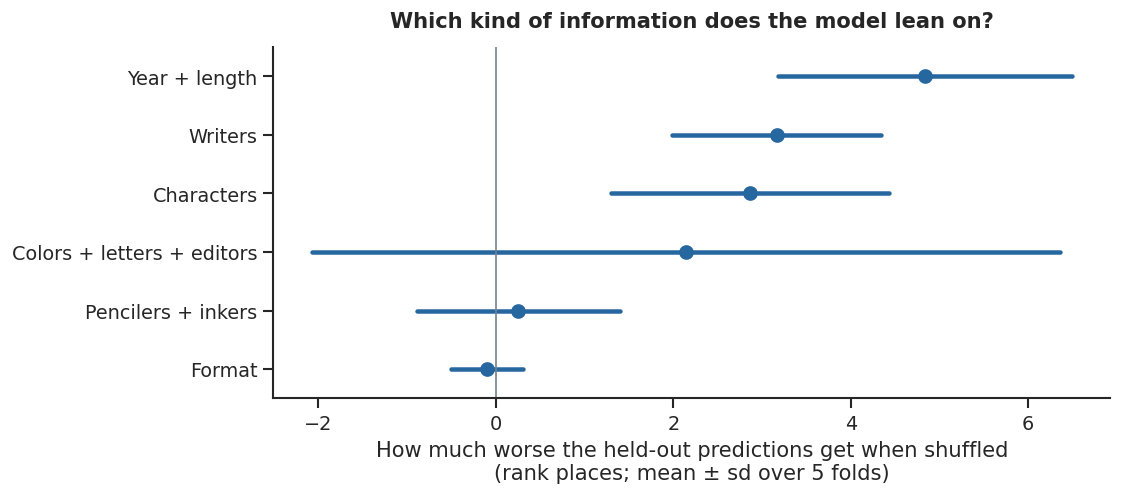

In [5]:
order = shuffle_cost.groupby("block")["worse by"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.pointplot(
    data=shuffle_cost,
    x="worse by",
    y="block",
    order=order,
    errorbar="sd",
    linestyle="none",
    color=BLUE,
    ax=ax,
)
ax.axvline(0, color=GREY, lw=1)
ax.set(
    xlabel="How much worse the held-out predictions get when shuffled\n(rank places; mean ± sd over 5 folds)",
    ylabel="",
    title="Which kind of information does the model lean on?",
)
plt.show()

Year and length form one shuffled block, so this test cannot separate their effects. The typical prediction miss is about 170 places; changes of a few places are modest.

## 2a. Big effect, or a frequently useful feature?

A name coefficient describes switching that input on; year and issue count are scaled, so their coefficients describe a one-standard-deviation change. **Mean absolute held-out SHAP** measures how much a feature contributes across this actual set of stories, including when it is absent. A rare feature can have a large coefficient but little overall influence.

The left panel ranks features by that overall magnitude. The right shows the **signed mean contribution when present**: positive points toward a higher BatChat score (a better rank), negative toward a worse one. Continuous features use all stories, so their signed average can be near zero even when they matter greatly.

Each label gives the observed story count and the number of linked issue/episode groups containing it. Thin intervals are **95% cluster-bootstrap intervals** for the signed mean, holding the fitted predictions fixed; fewer than five groups gets no interval. The table adds the range across five held-out folds and the number of fits that retained the feature. Wide ranges, few groups, or omission from some fits are reasons for caution—not evidence of a precise effect.

Credits and characters are correlated, so these are model attributions, not causal effects. Continuity variants are combined within each displayed name and role before taking absolute values. Missing cast or credits are not verified absences.

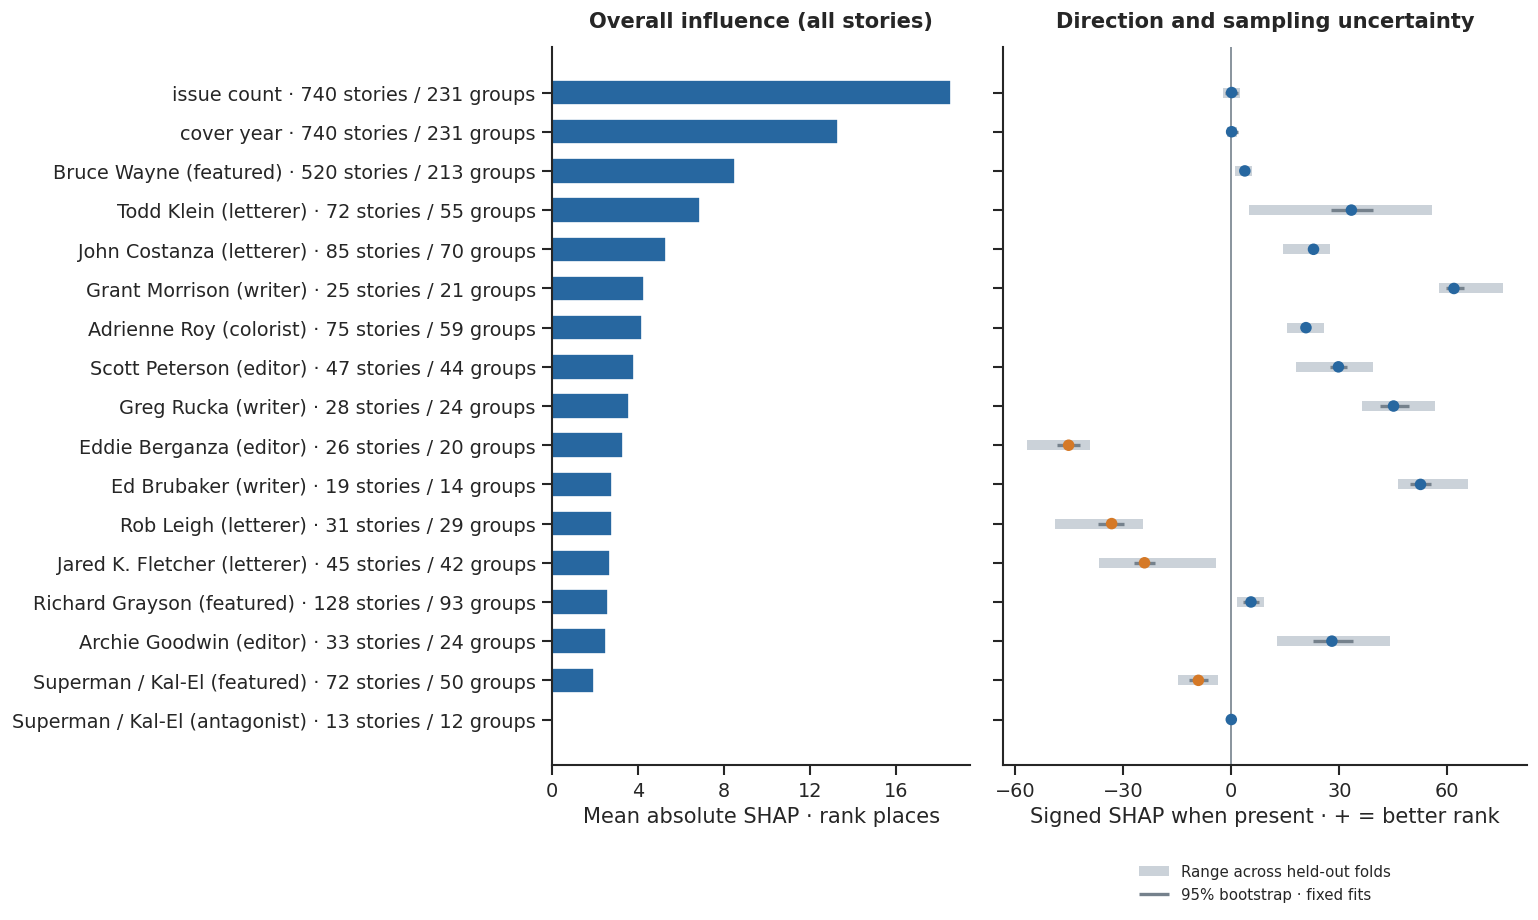

,Stories,Groups,Fits retaining feature,Mean |SHAP| (all),Mean |SHAP| (present),Signed mean (present),Fold minimum,Fold maximum,Folds with presence
issue count,740,231,5,18.5,18.5,0.1,-2.4,2.4,5
cover year,740,231,5,13.3,13.3,0.1,-1.3,1.5,5
Bruce Wayne (featured),520,213,5,8.5,8.9,3.8,1.1,5.8,5
Todd Klein (letterer),72,55,5,6.9,33.4,33.4,4.8,55.8,5
John Costanza (letterer),85,70,5,5.3,22.8,22.8,14.4,27.3,5
Grant Morrison (writer),25,21,5,4.3,61.8,61.8,57.7,75.4,5
Adrienne Roy (colorist),75,59,5,4.2,20.7,20.7,15.5,25.7,5
Scott Peterson (editor),47,44,5,3.8,29.8,29.8,18.1,39.5,5
Greg Rucka (writer),28,24,5,3.6,45.1,45.1,36.4,56.7,5
Eddie Berganza (editor),26,20,5,3.3,45.2,-45.2,-56.7,-39.3,5


Kal-El is indexed as featured or antagonist in 75 of 740 stories (53 validation groups). Roles above overlap; do not add their counts.
Counts cover Kal-El continuity variants in those two input fields; Kal-L variants and robots are separate names.


In [6]:
# Exact interventional SHAP for a linear model, relative to each training-fold mean.
# Keep zero contributions where a fold never learned a rare feature.
shap_parts, fold_ids, learned = [], np.empty(N, dtype=int), []
for k, (fitted, (train, test)) in enumerate(zip(fold_models, folds)):
    train_features = fitted[0].transform(X.iloc[train])
    test_features = fitted[0].transform(X.iloc[test])
    train_features = (
        train_features.toarray() if hasattr(train_features, "toarray") else train_features
    )
    test_features = test_features.toarray() if hasattr(test_features, "toarray") else test_features
    center = train_features.mean(axis=0)
    values = (test_features - center) * fitted[-1].coef_
    baseline = fitted[-1].intercept_ + center @ fitted[-1].coef_
    assert np.allclose(baseline + values.sum(axis=1), held_out[test])
    names = fitted[0].get_feature_names_out()
    shap_parts.append(
        pd.DataFrame(values, index=test, columns=names)
        .rename(columns=pretty)
        .T.groupby(level=0)
        .sum()
        .T
    )
    learned.append(set(map(pretty, names)))
    fold_ids[test] = k
held_shap = pd.concat(shap_parts).fillna(0).sort_index()

# Count raw observed names, including those below a fold's vocabulary threshold.
observed = {}
for column, kind in {**NAMES, **CAST}.items():
    for i, values in enumerate(X[column]):
        for token in values.split("|"):
            if token:
                observed.setdefault(pretty(kind + "__" + token), set()).add(i)
# Non-name features use their transformed nonzero indicator; continuous features use all rows.
presence = pd.DataFrame(False, index=stories.index, columns=held_shap.columns)
for name, rows in observed.items():
    if name in presence:
        presence.loc[list(rows), name] = True
for k, (fitted, (_, test)) in enumerate(zip(fold_models, folds)):
    values = fitted[0].transform(X.iloc[test])
    values = values.toarray() if hasattr(values, "toarray") else values
    for j, feature in enumerate(fitted[0].get_feature_names_out()):
        if feature.startswith("format__"):
            presence.loc[test, pretty(feature)] = values[:, j] != 0
presence[["cover year", "issue count"]] = True
support = pd.DataFrame(
    {
        "Stories": presence.sum(),
        "Groups": {name: len(set(groups[presence[name].to_numpy()])) for name in presence},
        "Mean |SHAP| (all)": held_shap.abs().mean(),
        "Mean |SHAP| (present)": held_shap.abs().where(presence).mean(),
        "Signed mean (present)": held_shap.where(presence).mean(),
        "Fits retaining feature": {
            name: sum(name in names for names in learned) for name in held_shap
        },
    }
)
fold_means = held_shap.where(presence).groupby(fold_ids).mean()
support["Fold minimum"] = fold_means.min()
support["Fold maximum"] = fold_means.max()
support["Folds with presence"] = fold_means.notna().sum()
# Top 15 overall, plus both Superman roles even when outside the top 15.
selected = list(support.nlargest(15, "Mean |SHAP| (all)").index)
selected += [name for name in support.index if name.startswith("Kal-El (") and name not in selected]
chart = support.loc[selected].sort_values("Mean |SHAP| (all)", ascending=False).copy()

# Resample connected issue/episode groups together, preserving their within-group stories.
group_sums = held_shap[selected].where(presence[selected], 0).groupby(groups).sum()
group_counts = presence[selected].groupby(groups).sum()
rng = np.random.default_rng(42)
weights = rng.multinomial(len(group_sums), np.full(len(group_sums), 1 / len(group_sums)), size=1000)
counts = weights @ group_counts.to_numpy()
means = np.divide(
    weights @ group_sums.to_numpy(), counts, out=np.full(counts.shape, np.nan), where=counts > 0
)
intervals = pd.DataFrame(
    np.nanquantile(means, [0.025, 0.975], axis=0).T, index=selected, columns=["95% low", "95% high"]
)
chart = chart.join(intervals)
chart.loc[chart.Groups.lt(5), ["95% low", "95% high"]] = np.nan

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 0.38 * len(chart) + 1.4),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1.25]},
)
ypos = np.arange(len(chart))
labels = [
    f"{name.replace('Kal-El', 'Superman / Kal-El')} · {int(row.Stories)} stories / {int(row.Groups)} groups"
    for name, row in chart.iterrows()
]
axes[0].barh(ypos, chart["Mean |SHAP| (all)"], color=BLUE, height=0.65)
axes[0].set(
    yticks=ypos,
    yticklabels=labels,
    xlabel="Mean absolute SHAP · rank places",
    title="Overall influence (all stories)",
)
colors = np.where(chart["Signed mean (present)"].ge(0), BLUE, ORANGE)
axes[1].hlines(
    ypos,
    chart["Fold minimum"],
    chart["Fold maximum"],
    color="#CBD2D9",
    linewidth=6,
    label="Range across held-out folds",
)
axes[1].hlines(
    ypos,
    chart["95% low"],
    chart["95% high"],
    color=GREY,
    linewidth=2,
    label="95% bootstrap · fixed fits",
)
axes[1].scatter(chart["Signed mean (present)"], ypos, c=colors, s=35, zorder=3)
axes[1].axvline(0, color=GREY, linewidth=1)
axes[1].set(
    xlabel="Signed SHAP when present · + = better rank", title="Direction and sampling uncertainty"
)
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(5))
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

from IPython.display import HTML, display

columns = [
    "Stories",
    "Groups",
    "Fits retaining feature",
    "Mean |SHAP| (all)",
    "Mean |SHAP| (present)",
    "Signed mean (present)",
    "Fold minimum",
    "Fold maximum",
    "Folds with presence",
]
display(
    HTML(
        "<details><summary>Support and fold stability for the plotted features</summary>"
        + chart[columns].round(1).to_html()
        + "</details>"
    )
)
superman = [name for name in observed if name.startswith("Kal-El (")]
superman_rows = set().union(*(observed[name] for name in superman))
print(
    f"Kal-El is indexed as featured or antagonist in {len(superman_rows)} of {N} stories "
    f"({len(set(groups[list(superman_rows)]))} validation groups). Roles above overlap; do not add their counts."
)
print(
    "Counts cover Kal-El continuity variants in those two input fields; Kal-L variants and robots are separate names."
)

Grant Morrison shows why magnitude and reach differ: his writer attribution averages about **+62 rank places when present**, across 25 stories and 21 groups, but only **4.3 places across the whole list**. Its signed means remain positive in all five held-out folds. Todd Klein has a smaller present contribution but greater overall influence because his credits reach more stories.

Superman / Kal-El is indexed as featured in 72 stories across 50 groups, with a modest negative mean contribution (about −9 places). His antagonist role appears in 13 stories, but only one fit retains a qualifying continuity variant. Its near-zero contribution mostly reflects the frequency screen; it does not establish that antagonist Superman has no relationship with the ranking.


## 2b. Does a small boosted tree help?

One XGBoost configuration, on the **same held-out folds and inputs** as ridge: 200 shallow trees, depth three, with at least ten training observations per leaf. Held-out error falls from **174.1 to 169.6 rank places**, with an improvement in all five folds. This is a modest gain from one fixed configuration, without a tuning search.

[Native TreeSHAP](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.predict) supplies the contributions and interactions, so no separate SHAP package is needed. Its tree-path background differs from the ridge panel's training-mean background; compare the patterns, not individual attribution numbers as if they had an identical reference.

Each dot is one held-out story. Colors run from low to high within a numeric feature, or from not indexed to indexed for names; grey numeric dots have missing metadata. Dot spread shows variation across stories, not a confidence interval.

,Average miss (rank places)
Training-fold average,185.5
Ridge,174.1
Shallow XGBoost,169.6


XGBoost 3.2.0: lower error in 5 of 5 folds; no parameter search.


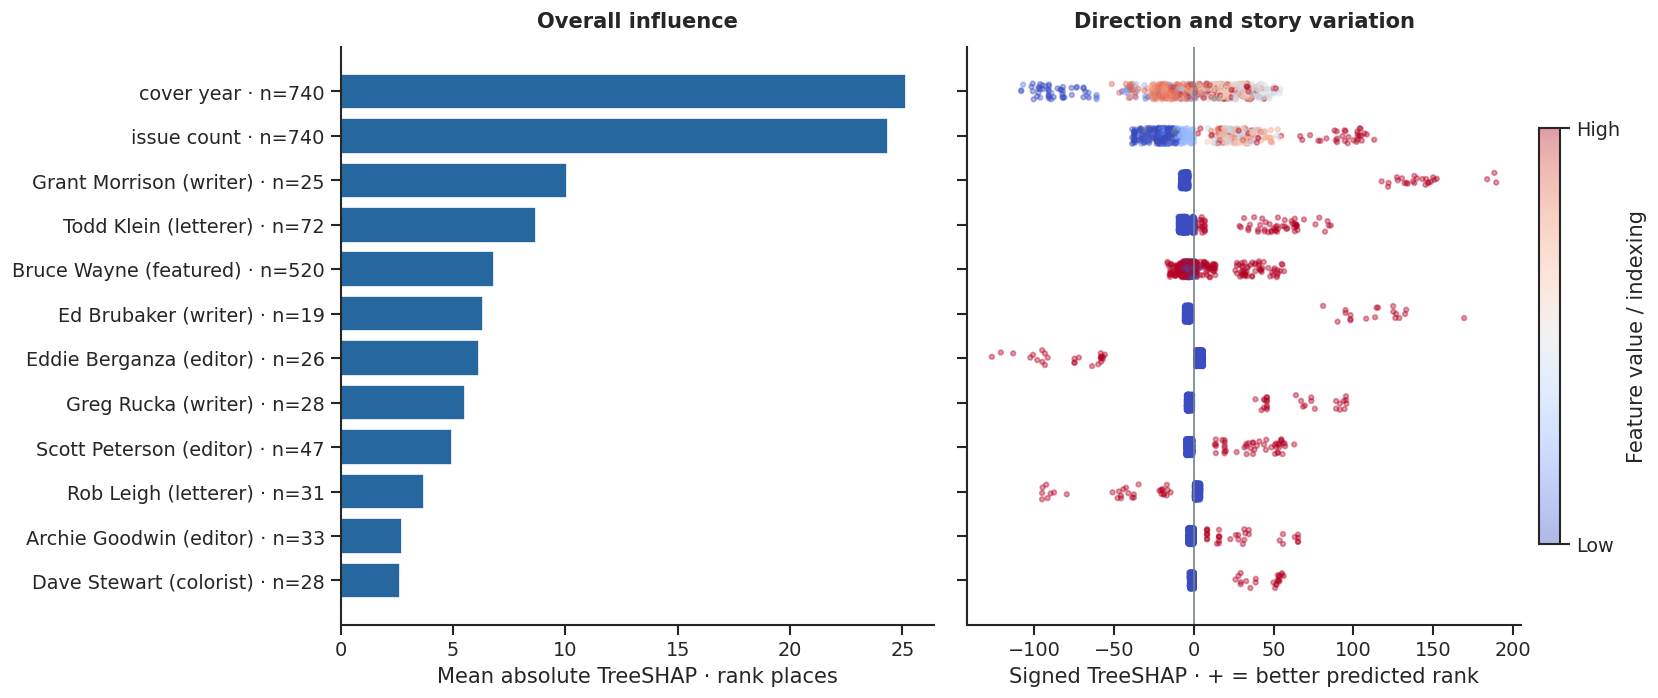

In [7]:
import xgboost as xgb

# Reuse training-only encoders; dense arrays keep zero indicators distinct from tree missing values.
tree_predictions = np.empty(N)
baseline_predictions = np.empty(N)
tree_runs, tree_parts = [], []
params = dict(
    objective="reg:squarederror",
    tree_method="hist",
    max_depth=3,
    eta=0.05,
    min_child_weight=10,
    reg_lambda=10,
    subsample=0.8,
    colsample_bytree=0.8,
    seed=42,
    nthread=2,
)
for fitted, (train, test) in zip(fold_models, folds):
    a, b = fitted[0].transform(X.iloc[train]), fitted[0].transform(X.iloc[test])
    a = np.asarray(a.toarray() if hasattr(a, "toarray") else a, dtype="float32")
    b = np.asarray(b.toarray() if hasattr(b, "toarray") else b, dtype="float32")
    booster = xgb.train(params, xgb.DMatrix(a, label=y.iloc[train]), num_boost_round=200)
    data = xgb.DMatrix(b)
    tree_predictions[test] = booster.predict(data)
    baseline_predictions[test] = y.iloc[train].mean()
    values = booster.predict(data, pred_contribs=True)
    assert np.allclose(values.sum(axis=1), tree_predictions[test], atol=0.002)
    names = fitted[0].get_feature_names_out().tolist()
    tree_parts.append(pd.DataFrame(values[:, :-1], index=test, columns=names))
    tree_runs.append((booster, data, names, test, values))
raw_tree_shap = pd.concat(tree_parts).fillna(0).sort_index()
tree_shap = raw_tree_shap.rename(columns=pretty).T.groupby(level=0).sum().T
errors = pd.Series(
    {
        name: mean_absolute_error(y, prediction)
        for name, prediction in {
            "Training-fold average": baseline_predictions,
            "Ridge": held_out,
            "Shallow XGBoost": tree_predictions,
        }.items()
    },
    name="Average miss (rank places)",
)
display(errors.round(1).to_frame())
wins = sum(
    mean_absolute_error(y.iloc[test], tree_predictions[test])
    < mean_absolute_error(y.iloc[test], held_out[test])
    for _, test in folds
)
print(
    f"XGBoost {xgb.__version__}: lower error in {wins} of {len(folds)} folds; no parameter search."
)
importance = tree_shap.abs().mean().nlargest(12).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(
    [f"{name} · n={int(support.loc[name, 'Stories'])}" for name in importance.index],
    importance,
    color=BLUE,
)
axes[0].set(xlabel="Mean absolute TreeSHAP · rank places", title="Overall influence")
rng = np.random.default_rng(42)
colors = plt.get_cmap("coolwarm").copy()
colors.set_bad(GREY)
for pos, name in enumerate(importance.index):
    if name in {"cover year", "issue count"}:
        raw = X["cover_year_start" if name == "cover year" else "issue_count"]
        low, high = raw.quantile([0.05, 0.95])
        level = ((raw - low) / max(high - low, 1)).clip(0, 1)
    else:
        level = presence[name].astype(float)
    dots = axes[1].scatter(
        tree_shap[name],
        pos + rng.uniform(-0.18, 0.18, N),
        c=level,
        cmap=colors,
        vmin=0,
        vmax=1,
        s=8,
        alpha=0.4,
        plotnonfinite=True,
    )
axes[1].axvline(0, color=GREY, linewidth=1)
axes[1].set(
    xlabel="Signed TreeSHAP · + = better predicted rank", title="Direction and story variation"
)
bar = fig.colorbar(dots, ax=axes[1], ticks=[0, 1], fraction=0.035, pad=0.03)
bar.ax.set_yticklabels(["Low", "High"])
bar.set_label("Feature value / indexing")
fig.tight_layout()
plt.show()

Year and length remain the biggest influences across the list. Morrison's indexed stories usually push the tree prediction up, but there are only **25** of them.

## 2c. Which combinations matter?

An interaction is the part of the model contribution that cannot be assigned to either input alone. We screen pairs among its 20 most influential numeric/name features. The table keeps pairs with **eight jointly observed stories, five linked groups and nonzero interactions in at least four fits**. These are exploratory screens, not significance tests. Continuity variants stay separate here.

Below, grey cells have too little support. Both panels use the observed books with known year and length; none are synthetic creator/era combinations. The right panel shows the **extra pair term**, not the total prediction: a negative cell can still contain highly ranked stories.

,Mean |pair| (all),Joint stories,Linked groups,Folds
Pair,,,,
cover year × issue count,6.94,719,231,5
issue count × Adrienne Roy (colorist),1.87,74,58,5
issue count × Scott Peterson (editor),1.23,46,43,5
issue count × Todd Klein (letterer),1.18,71,54,5
cover year × Bruce Wayne (Prime Earth) (featured),1.09,67,55,5
cover year × John Costanza (letterer),0.67,85,70,5


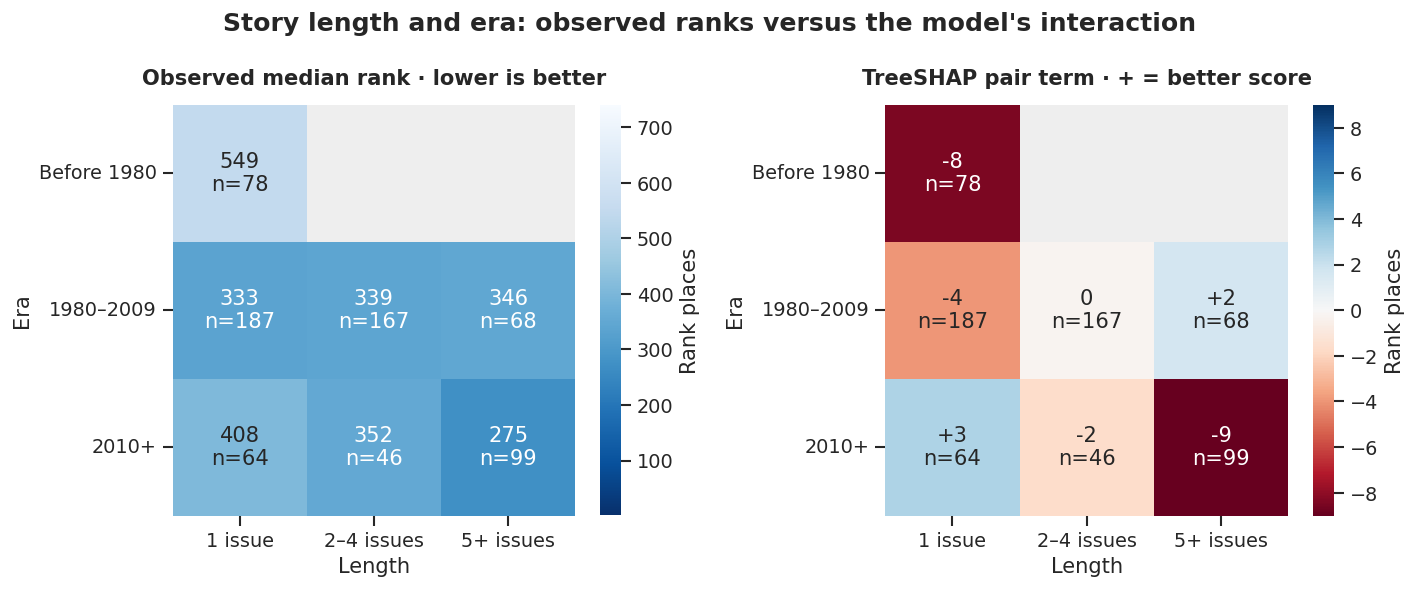

In [8]:
# Screen at most 190 pairs among the 20 most influential numeric/name inputs.
from itertools import combinations

eligible = [name for name in raw_tree_shap if not name.startswith("format__")]
leading = raw_tree_shap[eligible].abs().mean().nlargest(20).index.tolist()
pair_parts, year_length = [], np.zeros(N)
for booster, data, names, test, values in tree_runs:
    interactions = booster.predict(data, pred_interactions=True)
    assert np.allclose(interactions.sum(axis=2), values, atol=0.002)
    positions = {name: i for i, name in enumerate(names)}
    pair_parts.append(
        pd.Series(
            {
                (a, b): np.abs(2 * interactions[:, positions[a], positions[b]]).sum() / N
                for a, b in combinations(leading, 2)
                if a in positions and b in positions
            }
        )
    )
    # Off-diagonal terms split a pair in half; use both halves for its full contribution.
    year_length[test] = (
        2 * interactions[:, positions["num__cover_year_start"], positions["num__issue_count"]]
    )
    del interactions
pair_folds = pd.concat(pair_parts, axis=1).fillna(0)
name_columns = {kind: column for column, kind in {**NAMES, **CAST}.items()}
pair_presence, labels = {}, {}
for feature in leading:
    kind, _, value = feature.partition("__")
    pair_presence[feature] = (
        X[value].notna().to_numpy()
        if kind == "num"
        else X[name_columns[kind]]
        .str.split("|", regex=False)
        .map(lambda names: value in names)
        .to_numpy()
    )
    labels[feature] = pretty(feature) if kind == "num" else f"{value} ({kind})"
rows = []
for (a, b), contributions in pair_folds.iterrows():
    present = pair_presence[a] & pair_presence[b]
    stories_n, groups_n = int(present.sum()), len(set(groups[present]))
    active_folds = int(contributions.gt(0).sum())
    if stories_n >= 8 and groups_n >= 5 and active_folds >= 4:
        rows.append(
            {
                "Pair": labels[a] + " × " + labels[b],
                "Mean |pair| (all)": contributions.sum(),
                "Joint stories": stories_n,
                "Linked groups": groups_n,
                "Folds": active_folds,
            }
        )
pair_table = pd.DataFrame(rows).set_index("Pair").sort_values("Mean |pair| (all)", ascending=False)
display(pair_table.head(6).round(2))

# Compare observed books with their held-out model interaction, without inventing combinations.
profile = (
    pd.DataFrame(
        {
            "Era": pd.cut(
                X.cover_year_start,
                [-np.inf, 1980, 2010, np.inf],
                right=False,
                labels=["Before 1980", "1980–2009", "2010+"],
            ),
            "Length": pd.cut(
                X.issue_count, [0, 1, 4, np.inf], labels=["1 issue", "2–4 issues", "5+ issues"]
            ),
            "Rank": stories["rank"],
            "Pair contribution": year_length,
            "Group": groups,
        }
    )
    .groupby(["Era", "Length"], observed=True)
    .agg(
        stories=("Rank", "size"),
        groups=("Group", "nunique"),
        median_rank=("Rank", "median"),
        contribution=("Pair contribution", "mean"),
    )
)
profile = profile[profile.stories.ge(8) & profile.groups.ge(5)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, field, title in zip(
    axes,
    ["median_rank", "contribution"],
    ["Observed median rank · lower is better", "TreeSHAP pair term · + = better score"],
):
    grid = profile[field].unstack("Length")
    counts = profile.stories.unstack("Length").reindex_like(grid)
    annotations = grid.map(
        lambda v: (
            ""
            if pd.isna(v)
            else ("0" if abs(v) < 0.5 else f"{v:+.0f}")
            if field == "contribution"
            else f"{v:.0f}"
        )
    )
    annotations += counts.map(lambda v: "" if pd.isna(v) else f"\nn={v:.0f}")
    sns.heatmap(
        grid,
        annot=annotations,
        fmt="",
        mask=grid.isna(),
        ax=ax,
        cmap="RdBu" if field == "contribution" else "Blues_r",
        center=0 if field == "contribution" else None,
        vmin=-np.ceil(grid.abs().max().max()) if field == "contribution" else 1,
        vmax=np.ceil(grid.abs().max().max()) if field == "contribution" else N,
        cbar_kws={"label": "Rank places"},
    )
    ax.set_title(title)
    ax.set_facecolor("#EEEEEE")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle(
    "Story length and era: observed ranks versus the model's interaction", fontweight="bold"
)
fig.tight_layout()
plt.show()

Length is not one uniform signal. Among 1980–2009 books, the three length groups have median ranks around **333–346**. For 2010 onward, the median is **275** for five-plus issues versus **408** for one issue. The model's year–length interaction is largest among the screened pairs; for recent long stories it subtracts about **nine score places** from what the main effects would supply, tempering an otherwise favorable prediction.

That is a readable pattern, but a small one beside an average miss of about **170 places**. The credit-related pairs are smaller and can still identify runs or eras. These results do not establish a creator-team effect.

## 3. Ridge across audiences

The table separates ratings found, complete same-story matches and the final review-count screen. The outside audiences cover different books; these are exploratory comparisons. Categorical coefficients need eight observed stories to appear below. The smaller fits retain the existing three-story name minimum: some audiences have no penciler or inker with eight stories. Hidden rare coefficients still enter those fits.

Panels show the strongest coefficients in each audience's own units, keeping continuity variants separate.

,Any rating,Same story + complete,Passes review minimum
Audience,,,
Goodreads readers (stars),70,52,52
RoundUp readers (score /10),390,271,147
RoundUp critics (score /10),227,149,110


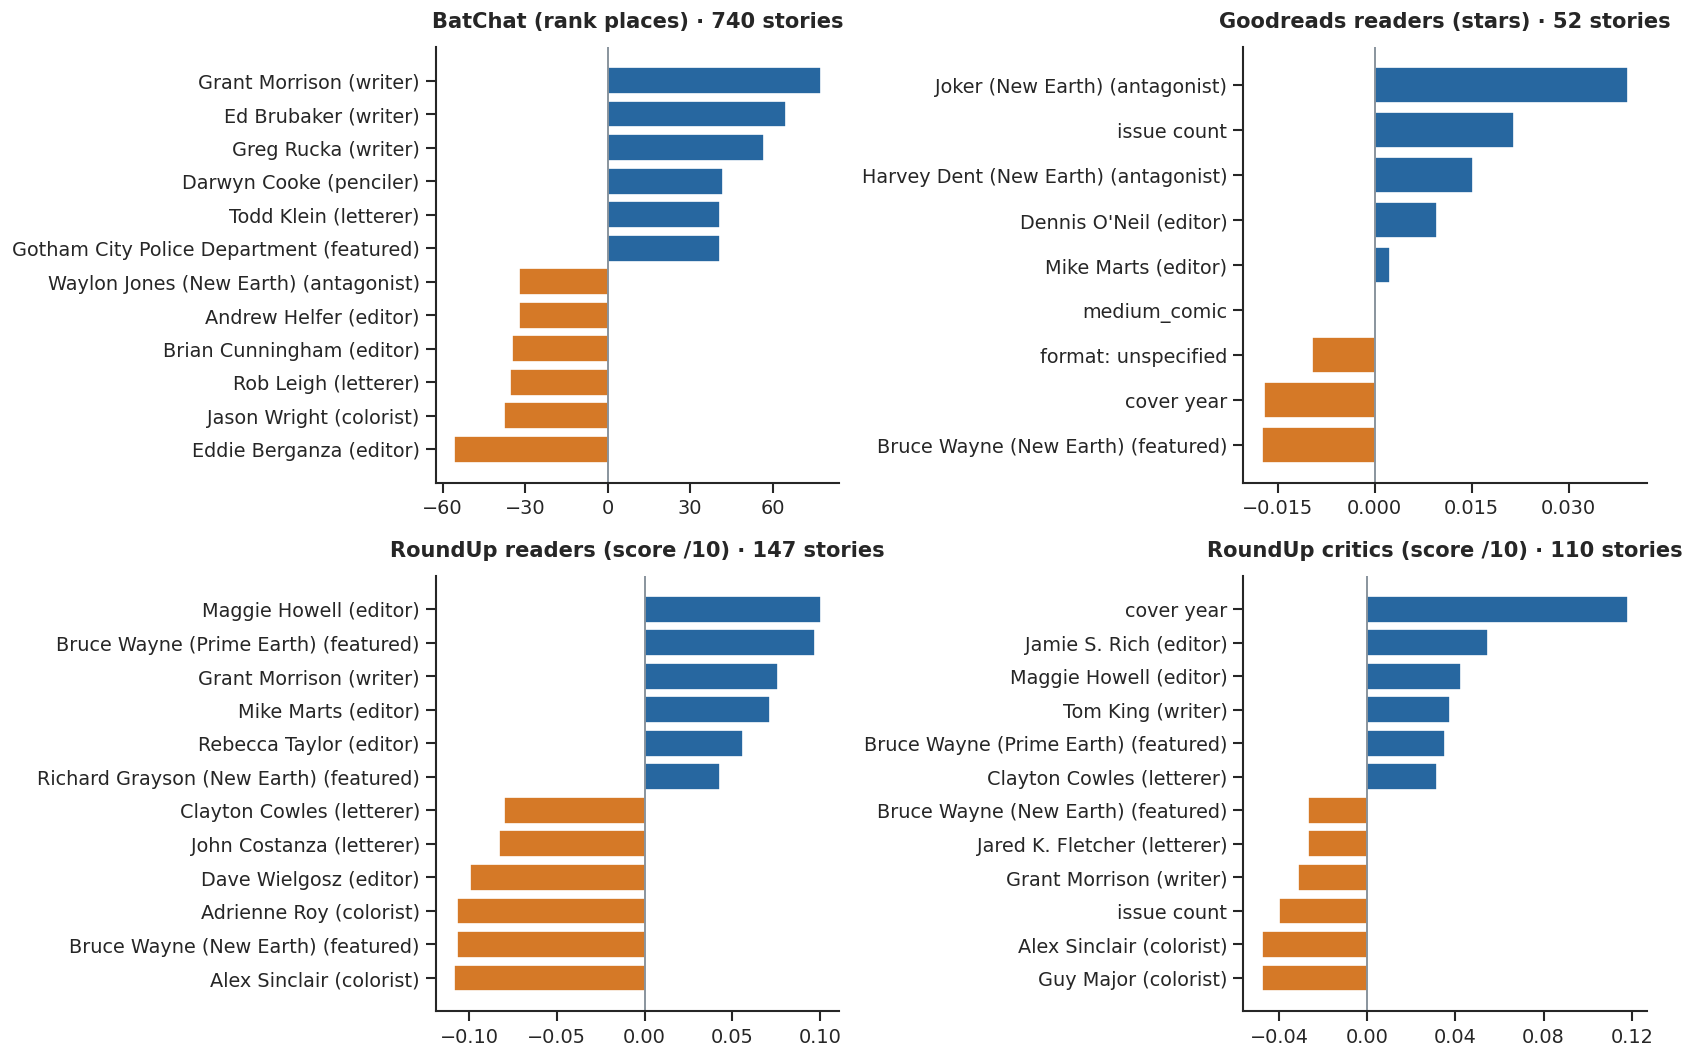

In [9]:
goodreads_ok = stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(
    100
)
roundup_ok = stories.roundup_narrative_scope.eq("all_indexed_narratives")
audiences = {
    "Goodreads readers (stars)": ("goodreads_rating", goodreads_ok),
    "RoundUp readers (score /10)": (
        "roundup_user_rating",
        roundup_ok & stories.roundup_user_complete & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics (score /10)": (
        "roundup_critic_rating",
        roundup_ok & stories.roundup_critic_complete & stories.roundup_critic_min_count.ge(3),
    ),
}
# Acquisition coverage and the final comparison sample are different counts.
coverage = []
for label, (score, ok) in audiences.items():
    if label.startswith("Goodreads"):
        comparable = stories.goodreads_match_scope.eq("same_story")
    else:
        audience = "critic" if "critic" in label.lower() else "user"
        comparable = roundup_ok & stories[f"roundup_{audience}_complete"]
    coverage.append(
        {
            "Audience": label,
            "Any rating": int(stories[score].notna().sum()),
            "Same story + complete": int((comparable & stories[score].notna()).sum()),
            "Passes review minimum": int(ok.sum()),
        }
    )
display(pd.DataFrame(coverage).set_index("Audience"))

audience_weights = {"BatChat (rank places)": batchat_weights}
for label, (target, ok) in audiences.items():
    fitted = model(min_df=3).fit(X[ok], stories.loc[ok, target])
    weights = weights_of(fitted)
    counts = np.asarray((fitted[0].transform(X[ok]) != 0).sum(axis=0)).ravel()
    show = [
        name.startswith("num__") or count >= MIN_STORIES
        for name, count in zip(fitted[0].get_feature_names_out(), counts)
    ]
    audience_weights[label] = weights.loc[show]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (label, w) in zip(axes.flat, audience_weights.items()):
    weight_bars(ax, w, 6)
    n = N if label.startswith("BatChat") else audiences[label][1].sum()
    ax.set_title(f"{label} · {n} stories")
fig.tight_layout()
plt.show()

The writer signal changes with the audience: Grant Morrison's coefficient is positive for BatChat and RoundUp readers, but slightly negative for RoundUp critics. These are different book samples and rating scales. The Goodreads panel is especially small: after matching and screening, only 52 stories remain, and even its strongest coefficients move predictions by only a few hundredths of a star.


## 4. Ridge: individual mismatches

Each panel uses the held-out fit that made that prediction. Left: the hosts liked the story more than predicted; right: less. Bars show the largest contributions from present features, so the displayed subset does not sum to the prediction. Each panel uses its own horizontal scale.

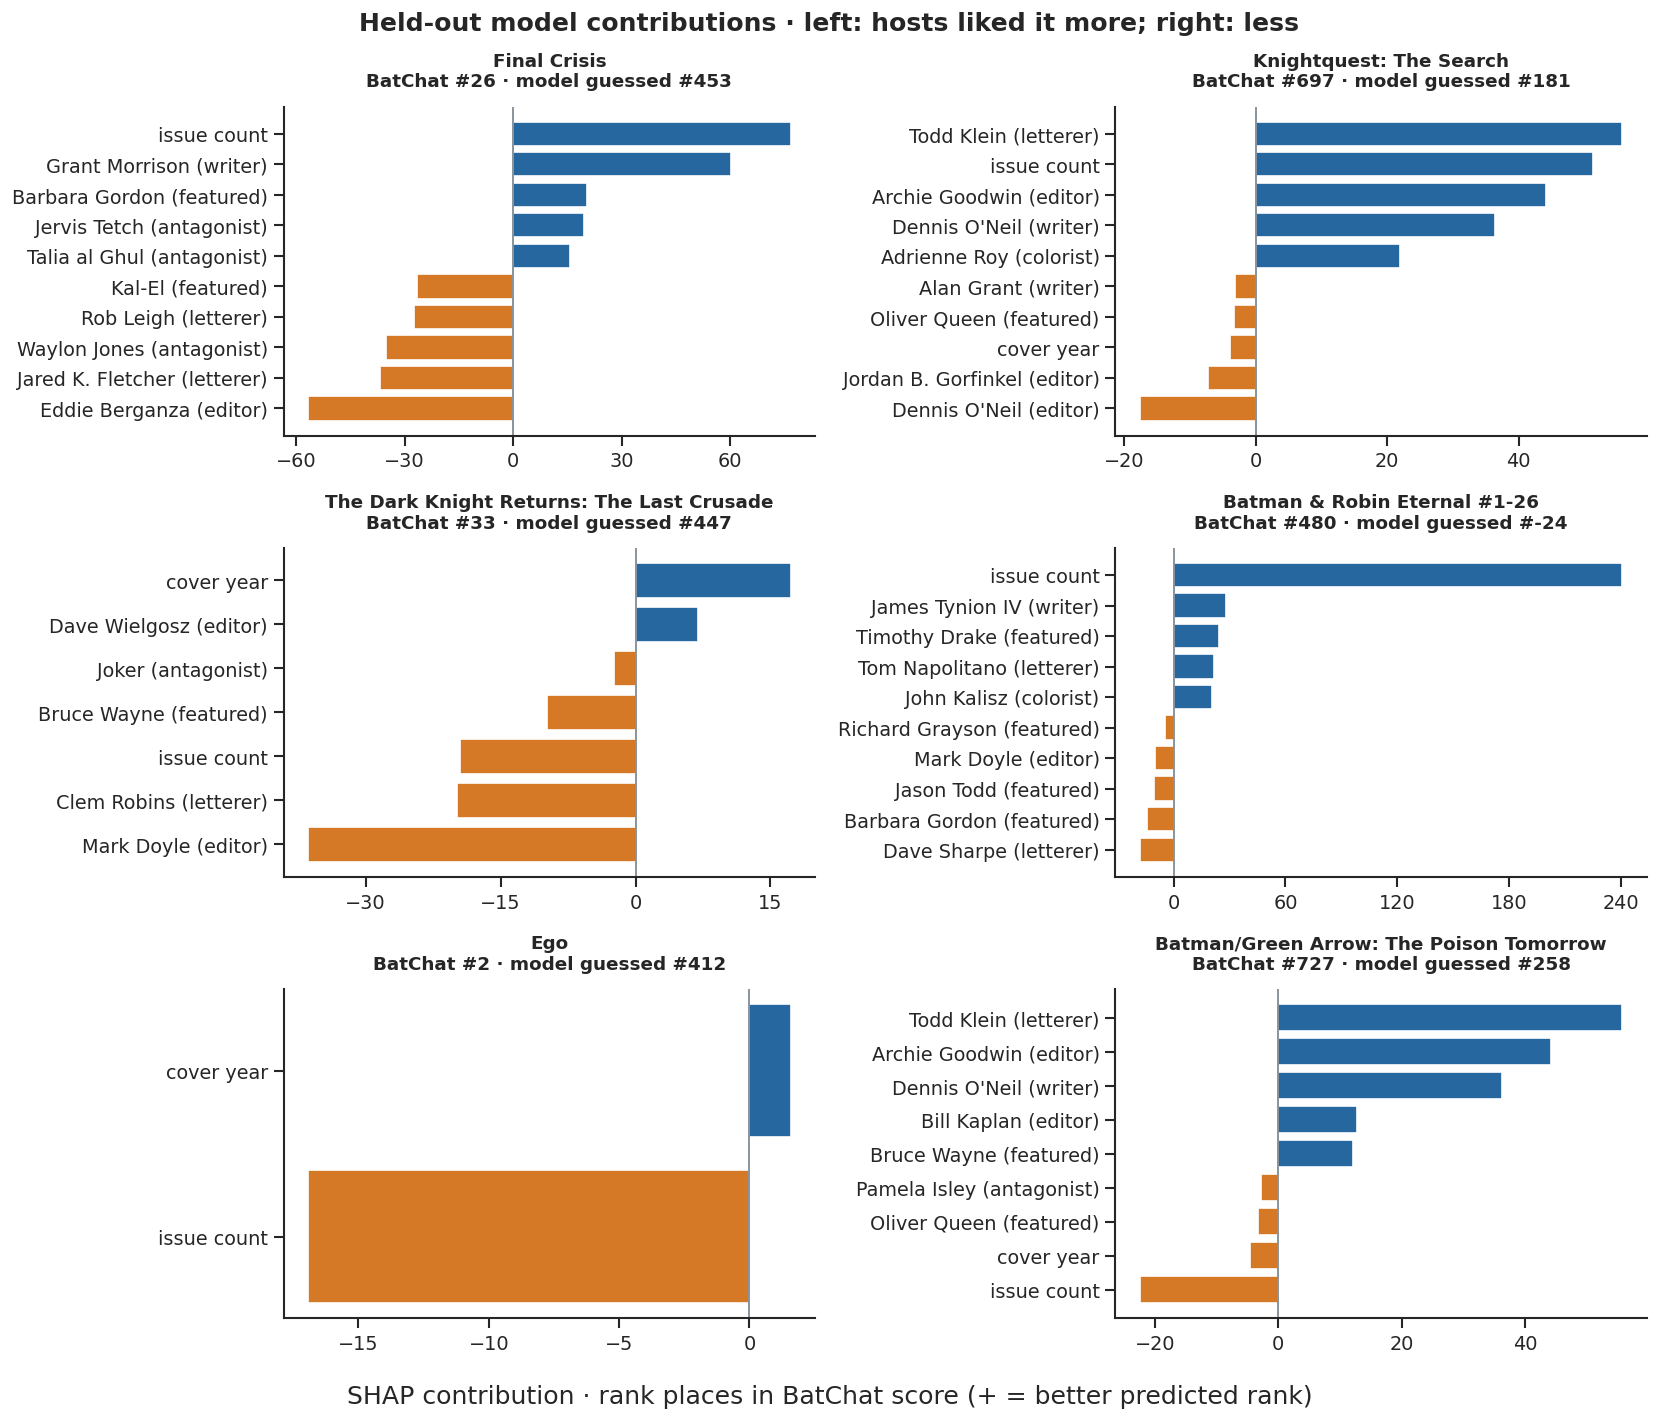

In [10]:
surprise = pd.Series(y.to_numpy() - held_out, index=stories.index)
picks = [*surprise.nlargest(3).index, *surprise.nsmallest(3).index]
contrib = held_shap.where(presence, 0)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, row in zip(axes.T.flat, picks):
    parts = contrib.loc[row]
    weight_bars(ax, parts[parts.abs() > 1], 5)
    title = stories.loc[row, "title"]
    rank = int(stories.loc[row, "rank"])
    guess = int(N - held_out[row])
    ax.set_title(f"{title}\nBatChat #{rank} · model guessed #{guess}", fontsize=11)
fig.suptitle(
    "Held-out model contributions · left: hosts liked it more; right: less", fontweight="bold"
)
fig.supxlabel("SHAP contribution · rank places in BatChat score (+ = better predicted rank)")
fig.tight_layout()
plt.show()

*Ego* (#2) reveals a cost of the frequency screen. Darwyn Cooke has only three training stories in its held-out fold as writer and as penciler, so neither role receives a coefficient there. The displayed present-feature contributions come only from year and length; the model guesses about #412. The full-data fit does include Cooke as a penciler: a recognizable creator can disappear from an individual explanation.

*Batman & Robin Eternal* (#480) exposes a different limitation: the model treats issue count as a linear effect. Its unusually long run can dominate the prediction. The reranking notebook examines these kinds of disagreements without treating the model as the correct ranking.

## What the evidence supports

- Magnitude and direction differ: a feature can matter strongly in a few books but little across the list.
- Story counts, linked groups and fold stability help distinguish a broad pattern from a fragile example.
- Both models still miss by about 170 places. Their attributions explain their predictions, not the hosts' reasoning.

<details><summary>Methods notes</summary>

- **Ridge:** ridge regression (the penalty chosen by cross-validation from 0.1 to 1000), the same set-up as [the prediction notebook](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories). BatChat names need eight training stories per fit; outside-audience fits keep three, with an eight-story display screen. This is a frequency screen, not evidence of eight independent runs. Targets: BatChat score (740 − rank), Goodreads stars, RoundUp scores.
- **Stability** keeps a coefficient only if its weight has the same sign and its absolute magnitude exceeds 10 in all five fold refits. A rough filter, not a significance test.
- **Shuffle test** scrambles whole groups of columns at once (`sklearn.inspection.permutation_importance` does the same one column at a time); each block keeps its shuffled columns together.
- **SHAP** for this linear model is weight × (value − background mean). Each explanation uses its held-out fit and training background. We verify that all contributions plus the baseline reconstruct the held-out prediction, then plot only the largest present-feature contributions.

</details>

Read next: [Twenty reranking cases](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) · [Audience comparisons](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree)